# Asset-Pricing Model Tests

A model can explain monthly return movements and still miss average returns. Asset-pricing tests ask whether its factors account for expected returns across a chosen set of investments. For traded factors, this also asks whether their tangency combination remains efficient when the test portfolios are available.

Notebook 04 examined individual candidate factors, 05 estimated cross-sectional compensation, and 06 developed portfolio efficiency. Here we bring those ideas together through joint time-series alpha restrictions and the Gibbons–Ross–Shanken test. We then compare CAPM, the supplied three-factor subset, and FF5 using the published 5×5 and 2×4×4 portfolios, examining pricing errors, return exposure, and the estimated expansion of investment opportunities.

In [10]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT / "src"))
from factor_asset_pricing.french_data import load_french, sample_coverage
RAW = ROOT / "data/raw/french"
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from factor_asset_pricing.asset_pricing_tests import factor_regressions, grs_test, pricing_error_summary

pd.options.display.float_format = "{:,.4f}".format
plt.style.use("seaborn-v0_8-whitegrid")
factors = load_french("ff5", RAW).loc["1963-07":"2024-12"]
assert len(factors) == 738 and not factors.isna().any().any()
sample_starts = {"size_bm": "1964-07", "size_op": "1964-07", "size_inv": "1963-07",
                 "size_bm_op": "1967-07", "size_bm_inv": "1964-07", "size_op_inv": "1964-07"}
portfolio_sets = {family: load_french(family, RAW).loc[start:"2024-12"] for family, start in sample_starts.items()}


## 1. Asset-pricing models and mean–variance efficiency

### 1.1 From factor spanning to model evaluation

Notebook 04 asks whether a candidate factor adds to a benchmark. Model evaluation instead asks whether the benchmark accounts for a deliberately chosen cross-section of investments.

Arbitrage Pricing Theory provided an influential motivation for multifactor pricing: with no arbitrage, a sufficiently broad factor structure, and diversifiable idiosyncratic risk, expected returns are approximately linear in systematic exposures rather than market beta alone. A complementary motivation comes from the Intertemporal CAPM. Investors care not only about current wealth, but also about changes in future investment opportunities. Assets may therefore earn risk premia for covarying with state variables that shift expected returns and volatility, changing the investor's future investment opportunities.

Empirical factors such as size, value, profitability, and investment can be treated as factor-mimicking portfolio returns that summarize common variation or proxy for otherwise difficult-to-observe state variables. However, neither APT nor the ICAPM uniquely identifies these particular factors, and mapping them to specific structural risks is not theoretically unambiguous. Whether they represent priced risks, behavioral mispricing, or useful empirical proxies consequently remains debated.

Even with that caveat, multifactor models are useful empirical benchmarks. They let us ask whether a new factor or a set of test portfolios is explained not only by the market, but also by established characteristic-related return dimensions. The CAPM contains MKT, FF3 adds SMB and HML. And FF5 adds RMW and CMA.

The three-factor benchmark here retains SMB from the supplied five-factor dataset. Since FF5 SMB averages the B/M, OP, and INV size spreads, it differs from the original FF3 size factor based on B/M sorts alone. “FF3” therefore denotes the nested MKT–SMB–HML benchmark actually estimated, rather than an exact reconstruction of the 1993 factor definitions.

### 1.2 Time-series pricing restrictions

Following the estimation framework in 04, for every test portfolio $i$, we estimate the same general time-series regression:

$$R_{i,t}-R_{f,t}=\alpha_i+\boldsymbol{\beta}_i'\mathbf F_t+\varepsilon_{i,t},$$

where $R_{i,t}$ is portfolio $i$'s total return, $R_{f,t}$ is the matching risk-free return, and $\mathbf F_t$ contains the model's traded factor returns. Alpha is the model's pricing error. For each portfolio, we test

$$H_0:\alpha_i=0 \qquad \text{against} \qquad H_1:\alpha_i\neq0.$$

A significant alpha provides evidence against the model's restriction on that portfolio's expected excess return. In model evaluation, small and statistically insignificant alphas are desirable—the opposite emphasis from a factor-spanning exercise, where researchers seek incremental alpha.

The loading $\beta_{i,k}$ measures portfolio $i$'s partial linear co-movement with factor $k$. We test $H_0:\beta_{i,k}=0$ against $H_1:\beta_{i,k}\neq0$. A significant positive loading indicates positive exposure to that factor return, holding the remaining factors fixed. It does not alone prove that the factor is a structural source of priced risk. Adjusted $R^2$ measures the fraction of monthly variation explained while penalizing additional regressors, but high fit does not guarantee small alphas.

For the population linear projection, $E[\varepsilon_{i,t}]=0$ and $E[\varepsilon_{i,t}\mathbf F_t]=\mathbf0$, giving $\alpha_i=E[R_{i,t}-R_{f,t}]-\boldsymbol\beta_i'E[\mathbf F_t]$. Unlike the freely fitted cross-sectional errors in 05, these alphas evaluate the traded-factor benchmark using its own mean returns. Constant sample loadings are not estimates of conditional betas that vary with the information set. Insignificant alphas can reflect limited power as well as small pricing errors.

### 1.3 Why test portfolios?

A factor model is evaluated on assets chosen to expose economically relevant cross-sectional variation. Sorting stocks into portfolios reduces firm-specific noise while preserving variation in characteristics and expected returns. The design is a balance: portfolios must differ enough to challenge the model, but each cell should contain enough firms for idiosyncratic shocks not to create unstable or spurious alphas.

The 5×5 portfolios independently sort firms into five size groups and five groups of B/M, OP, or INV. The 2×4×4 portfolios first split firms into small and big groups and then form quartiles on two additional characteristics within size. Notebook 02 explains characteristic-based portfolio formation. These higher-dimensional portfolios ask whether a model explains one characteristic while conditioning more explicitly on another. Each family is tested separately. GRS does **not** require the portfolios themselves to be uncorrelated—it explicitly uses their residual covariance—but pooling many overlapping families can create redundant assets, an ill-conditioned covariance matrix, and a joint test whose economic content is unclear.

Independent breakpoints do not imply independent characteristics or statistically independent cell returns. In the 2×4×4 construction, both additional characteristics use size-conditioned breakpoints. Their intersections need not have equal membership.

### 1.4 Joint alpha and investment efficiency

Notebook 06 connects expected excess returns and their covariance matrix to the maximum attainable squared Sharpe ratio. Applying that result to the factors alone and then to factors plus test portfolios gives a direct economic interpretation of joint alpha.

Let $\mathbf R_t$ contain the portfolio total returns, $R_{f,t}$ be the risk-free return, $\mathbf1$ a vector of ones, and $B$ the matrix of portfolio factor loadings. The vector of portfolio excess returns satisfies

$$(\mathbf R_t-R_{f,t}\mathbf1)=\boldsymbol\alpha+B\mathbf F_t+\boldsymbol\varepsilon_t.$$

Hedging the factor exposures leaves $(\mathbf R_t-R_{f,t}\mathbf1)-B\mathbf F_t$, with mean $\boldsymbol\alpha$ and covariance $\Sigma_\varepsilon$. Population projection residuals are uncorrelated with the factors. The investment set can therefore be represented by the factors and these hedged payoffs, giving

$$SR_{F+R}^2=SR_F^2+\boldsymbol\alpha'\Sigma_\varepsilon^{-1}\boldsymbol\alpha.$$

The final term is the increase in maximum squared Sharpe. Residual covariance matters because some alpha opportunities may overlap, while others diversify one another. An unweighted average of alphas cannot measure this aggregate investment contribution.

With positive-definite covariances, unrestricted long/short trading, and a risk-free asset, $\boldsymbol\alpha=\mathbf0$ means that the test portfolios do not improve the factors' maximum Sharpe ratio. Nonzero population alpha permits a strict improvement. The efficient benchmark is the factors' tangency combination, rather than each factor considered separately. This is mean–variance efficiency relative to the chosen added investments, not exact return replication or efficiency against every possible asset.

A nonzero estimated alpha vector almost always produces some in-sample Sharpe expansion. The statistical question is whether that estimated gain provides evidence of a population departure from efficiency. GRS addresses that question under its maintained assumptions.

### 1.5 The Gibbons–Ross–Shanken joint test

Gibbons, Ross, and Shanken (1989) test whether the model's alphas are jointly zero:

$$H_0:\boldsymbol\alpha=\mathbf0,\qquad H_1:\text{at least one }\alpha_i\ne0.$$

For traded-factor models under the assumptions in Section 1.4, this is also a test of whether the factors' tangency combination remains efficient when the test portfolios are available. It turns the investment question into a statistical restriction.

Let $T$ be the common sample size, $N$ the number of test portfolios, and $K$ the number of factors. Let $\widehat{\boldsymbol\alpha}$ collect the estimated regression intercepts, $\widehat\Sigma$ be the residual covariance matrix and $\widehat\Omega$ the factor covariance matrix. With both covariance matrices divided by $T$, the statistic follows

$$\frac{T-N-K}{N}\left(1+E_T(\mathbf F)'\widehat\Omega^{-1}E_T(\mathbf F)\right)^{-1}\widehat{\boldsymbol\alpha}'\widehat\Sigma^{-1}\widehat{\boldsymbol\alpha}\sim F_{N,T-N-K}.$$

Here $E_T(\mathbf F)$ denotes the sample factor mean. The quadratic form measures the estimated alphas jointly, accounting for their residual covariances. The factor term adjusts for estimation of factor exposures. Economically, the test assesses whether adding the test portfolios improves the factors' population mean–variance investment opportunity set.

Under the null, $GRS\sim F_{N,T-N-K}$ when regression errors are independent and identically distributed multivariate normal, with constant nonsingular covariance and independence from the factor regressors. The factor design must have full rank, the relevant covariances must be invertible, and $T>N+K$. Residuals can be correlated across portfolios.

Heteroskedasticity and serial dependence invalidate this conventional exact reference distribution. Reporting separate Newey–West alpha statistics does not make GRS robust. Rejection provides evidence against joint pricing and efficiency for the chosen family under the maintained assumptions. Failure to reject can also reflect limited power, rather than establish that the model is complete.

For individual-alpha inference, we retain the OLS coefficients and Newey–West standard errors from 04, with 12 monthly lags. The complementary model diagnostics are

$$A(|\alpha|)=\frac1N\sum_{i=1}^N|\widehat\alpha_i|,\qquad A(\bar R^2)=\frac1N\sum_{i=1}^N\bar R_i^2.$$

Absolute values prevent positive and negative pricing errors from cancelling. Root-mean-squared alpha additionally emphasizes large errors. Individual significance counts use unadjusted tests and are descriptive when many portfolios are tested. Neither high fit nor small average alpha, by itself, establishes efficiency.

## 2. Example: comparing CAPM, the three-factor subset, and FF5

### 2.1 Data and comparison conventions

We use published value-weighted 5×5 and 2×4×4 test portfolios from the [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html). We preserve the earlier starts: July 1964 for Size × B/M, Size × OP, Size × B/M × INV, and Size × OP × INV (726 months), and July 1967 for Size × B/M × OP (690 months). Size × INV begins July 1963 (738 months), since public FF5 cannot cover its earlier July 1962 start. All families end December 2024. Portfolio observations are total returns. Each family's matched RF is subtracted once, while the factors already contain excess-return payoffs.

CAPM, the supplied three-factor subset labeled FF3, and FF5 use identical dates within each portfolio family. Different families can have different complete histories, so their factor-only Sharpe ratios need not be identical. The FF3 label retains the existing comparison convention and uses five-factor SMB, as explained in Section 1.1.

### 2.2 Overall model comparison

The table summarizes the existing alpha, fit, and GRS results across all six families. We first assess the broad comparison, then examine the investment-efficiency gains and the patterns inside the individual portfolio designs.

In [11]:
models = {"CAPM": ["MKT"], "FF3": ["MKT", "SMB", "HML"], "FF5": ["MKT", "SMB", "HML", "RMW", "CMA"]}
labels = {"size_bm": "Size × B/M", "size_op": "Size × OP", "size_inv": "Size × INV", "size_bm_op": "Size × B/M × OP", "size_bm_inv": "Size × B/M × INV", "size_op_inv": "Size × OP × INV"}
aligned = {}
regressions = {}
joint_tests = {}
rows = []
for family, returns in portfolio_sets.items():
    sample = pd.concat([returns, factors], axis=1, join="inner").dropna()
    assert sample.index.equals(returns.index) and not sample.isna().any().any()
    assets = sample[returns.columns].sub(sample["RF"], axis=0)
    aligned[family] = (assets, sample)
    for model, columns in models.items():
        result = factor_regressions(assets, sample[columns], cov_type="HAC", hac_lags=12)
        regressions[family, model] = result
        grs = grs_test(assets, sample[columns])
        joint_tests[family, model] = grs
        errors = pricing_error_summary(result)
        rows.append({"Portfolio set": labels[family], "Model": model, "Mean |alpha| (% monthly)": 100*errors["mean_absolute_alpha"], "RMSE alpha (% monthly)": 100*errors["root_mean_squared_alpha"], "Mean adjusted R²": result.adjusted_r_squared.mean(), "Significant alphas (5%)": int((result.alpha_pvalue < .05).sum()), "GRS": grs["statistic"], "GRS p-value": grs["pvalue"]})
overview = pd.DataFrame(rows).set_index(["Portfolio set", "Model"])
display(overview)


Mean |alpha| (% monthly)  RMSE alpha (% monthly)  \
Portfolio set    Model                                                     
Size × B/M       CAPM                     0.1897                  0.2358   
                 FF3                      0.0933                  0.1388   
                 FF5                      0.0836                  0.1110   
Size × OP        CAPM                     0.1752                  0.1945   
                 FF3                      0.1086                  0.1363   
                 FF5                      0.0593                  0.0725   
Size × INV       CAPM                     0.2045                  0.2240   
                 FF3                      0.1016                  0.1386   
                 FF5                      0.0843                  0.1079   
Size × B/M × OP  CAPM                     0.2134                  0.2776   
                 FF3                      0.1275                  0.1740   
                 FF5                      0.0966                  0.1308   
Size × B/M × INV CAPM                     0.1826                  0.2243   
                 FF3                      0.1180                  0.1364   
                 FF5                      0.0874                  0.1124   
Size × OP × INV  CAPM                     0.2156                  0.2802   
                 FF3                      0.1613                  0.2087   
                 FF5                      0.0911                  0.1202   

                        Mean adjusted R²  Significant alphas (5%)    GRS  \
Portfolio set    Model                                                     
Size × B/M       CAPM             0.7392                        7 4.1106   
                 FF3              0.9153                        7 3.6976   
                 FF5              0.9196                        6 3.0828   
Size × OP        CAPM             0.7747                        2 2.1870   
                 FF3              0.8991                        7 2.4102   
                 FF5              0.9200                        3 1.8182   
Size × INV       CAPM             0.7765                       10 5.1313   
                 FF3              0.9180                        7 4.7855   
                 FF5              0.9295                        5 3.5848   
Size × B/M × OP  CAPM             0.6900                        4 2.1838   
                 FF3              0.8361                        7 2.0162   
                 FF5              0.8511                        6 1.5971   
Size × B/M × INV CAPM             0.7204                        7 2.9143   
                 FF3              0.8703                       11 2.7284   
                 FF5              0.8824                        6 2.3687   
Size × OP × INV  CAPM             0.7448                       16 3.9131   
                 FF3              0.8616                       16 3.6812   
                 FF5              0.8852                        7 2.3897   

                        GRS p-value  
Portfolio set    Model               
Size × B/M       CAPM        0.0000  
                 FF3         0.0000  
                 FF5         0.0000  
Size × OP        CAPM        0.0008  
                 FF3         0.0002  
                 FF5         0.0089  
Size × INV       CAPM        0.0000  
                 FF3         0.0000  
                 FF5         0.0000  
Size × B/M × OP  CAPM        0.0002  
                 FF3         0.0009  
                 FF5         0.0207  
Size × B/M × INV CAPM        0.0000  
                 FF3         0.0000  
                 FF5         0.0000  
Size × OP × INV  CAPM        0.0000  
                 FF3         0.0000  
                 FF5         0.0000

Across all six portfolio families, FF5 produces lower average absolute alpha and higher average adjusted $R^2$ than CAPM. The improvement is especially clear for portfolios involving profitability or investment, the two dimensions added to FF3. The comparison is not a mechanical reward for adding regressors: adjusted $R^2$ penalizes model size, while alpha remains the economically relevant pricing error. FF5 nevertheless remains imperfect. GRS rejects it for all six families at the 5% level. The earlier internal Size × OP portfolios failed to reject. The published portfolios now reject, illustrating sensitivity to the test-asset definitions.

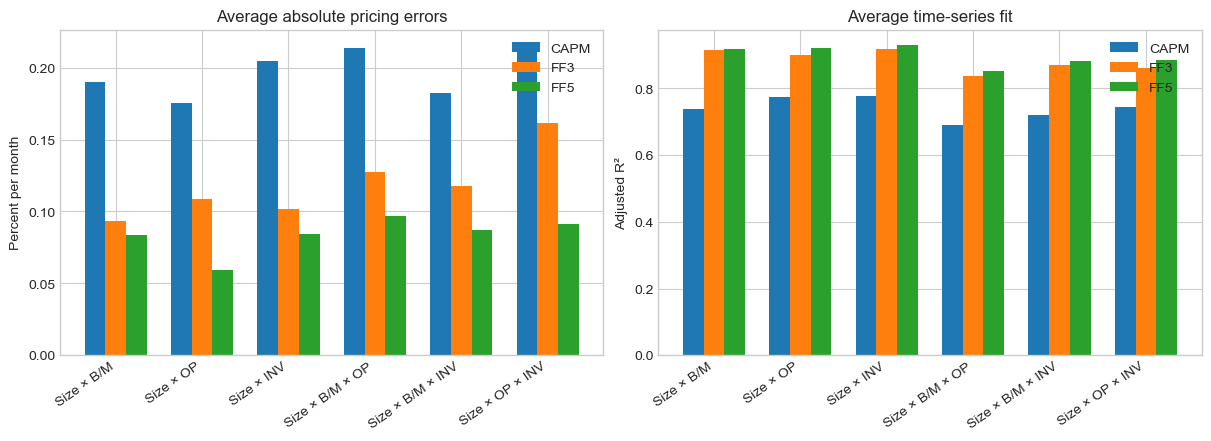

In [12]:
plot_data = overview.reset_index()
order = list(labels.values())
x = np.arange(len(order))
width = .24
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
for offset, model in zip([-width, 0, width], models):
    data = plot_data.set_index(["Portfolio set", "Model"]).loc[[(name, model) for name in order]].reset_index()
    axes[0].bar(x + offset, data["Mean |alpha| (% monthly)"], width, label=model)
    axes[1].bar(x + offset, data["Mean adjusted R²"], width, label=model)
for ax in axes:
    ax.set_xticks(x, order, rotation=35, ha="right")
    ax.legend(frameon=False)
axes[0].set(title="Average absolute pricing errors", ylabel="Percent per month")
axes[1].set(title="Average time-series fit", ylabel="Adjusted R²")
plt.show()


The visual comparison shows a broad rather than isolated improvement: moving from CAPM to FF3 and then FF5 generally compresses absolute alphas while increasing explanatory power. The remaining gap between small pricing errors and widespread GRS rejection illustrates why model evaluation should not be reduced to a single pass–fail statistic.

### 2.3 Do the test portfolios expand the investment opportunity set?

For every model and family, we compute the maximum Sharpe using the factors alone and then using factors plus that family's excess returns. Both calculations use exactly the sample retained for its GRS test, with divisor-$T-1$ covariance. Sharpe ratios and their squared differences are monthly and dimensionless.

The augmented combination permits signed positions in factors and test portfolios, with financing through the risk-free asset. We do not impose a common unit-sum constraint across this mixture of funded portfolios and constructed factor payoffs. Positive scaling changes its mean and volatility together without changing Sharpe. These maximum-Sharpe allocation lines therefore express the unrestricted efficiency comparison directly.

In [13]:
from factor_asset_pricing.asset_pricing_tests import maximum_sharpe_ratio

efficiency={}
efficiency_rows=[]
for family in labels:
    assets,sample=aligned[family]
    for model,columns in models.items():
        benchmark=sample[columns]
        augmented=pd.concat([benchmark,assets],axis=1)
        before=maximum_sharpe_ratio(benchmark,periods_per_year=1)
        after=maximum_sharpe_ratio(augmented,periods_per_year=1)
        grs=joint_tests[family,model]
        gain=after["sharpe"]**2-before["sharpe"]**2
        efficiency[family,model]={"factor_sharpe":before["sharpe"],
                                  "augmented_sharpe":after["sharpe"],
                                  "squared_gain":gain}
        efficiency_rows.append({"Portfolio set":labels[family],"Model":model,
                                "Factor SR":before["sharpe"],
                                "Augmented SR":after["sharpe"],
                                "Increase in SR²":gain,
                                "GRS":grs["statistic"],"GRS p-value":grs["pvalue"],
                                "Months":len(sample)})
efficiency_table=pd.DataFrame(efficiency_rows).set_index(["Portfolio set","Model"])
display(efficiency_table)

Factor SR  Augmented SR  Increase in SR²    GRS  \
Portfolio set    Model                                                    
Size × B/M       CAPM      0.1279        0.4066           0.1490 4.1106   
                 FF3       0.1764        0.4092           0.1364 3.6976   
                 FF5       0.2955        0.4556           0.1202 3.0828   
Size × OP        CAPM      0.1279        0.3092           0.0793 2.1870   
                 FF3       0.1764        0.3464           0.0889 2.4102   
                 FF5       0.2955        0.3978           0.0709 1.8182   
Size × INV       CAPM      0.1311        0.4474           0.1830 5.1313   
                 FF3       0.1815        0.4547           0.1738 4.7855   
                 FF5       0.2950        0.4737           0.1374 3.5848   
Size × B/M × OP  CAPM      0.1278        0.3525           0.1080 2.1838   
                 FF3       0.1764        0.3640           0.1014 2.0162   
                 FF5       0.3018        0.4200           0.0853 1.5971   
Size × B/M × INV CAPM      0.1279        0.3911           0.1366 2.9143   
                 FF3       0.1764        0.4015           0.1301 2.7284   
                 FF5       0.2955        0.4547           0.1195 2.3687   
Size × OP × INV  CAPM      0.1279        0.4469           0.1834 3.9131   
                 FF3       0.1764        0.4546           0.1755 3.6812   
                 FF5       0.2955        0.4559           0.1205 2.3897   

                        GRS p-value  Months  
Portfolio set    Model                       
Size × B/M       CAPM        0.0000     726  
                 FF3         0.0000     726  
                 FF5         0.0000     726  
Size × OP        CAPM        0.0008     726  
                 FF3         0.0002     726  
                 FF5         0.0089     726  
Size × INV       CAPM        0.0000     738  
                 FF3         0.0000     738  
                 FF5         0.0000     738  
Size × B/M × OP  CAPM        0.0002     690  
                 FF3         0.0009     690  
                 FF5         0.0207     690  
Size × B/M × INV CAPM        0.0000     726  
                 FF3         0.0000     726  
                 FF5         0.0000     726  
Size × OP × INV  CAPM        0.0000     726  
                 FF3         0.0000     726  
                 FF5         0.0000     726

Every added portfolio family increases the estimated maximum Sharpe ratio. This is an in-sample improvement and is expected even when population alphas are zero, because the larger investment set can exploit sampling noise. The GRS p-values assess the evidence against population efficiency under the test's conventional assumptions.

The Size × OP family illustrates the distinction. Adding its portfolios to FF5 raises monthly maximum Sharpe from approximately 0.295 to 0.398, yet GRS has a p-value of approximately 0.0089. The test now rejects the joint zero-alpha restriction at 5%, as do the other FF5 families, conditional on the same test assumptions. Failure to reject does not establish that no population opportunity remains.

The three panels below focus on Size × B/M using its common 726-month sample. Each compares the best factor-only combination with the best combination also allowed to hold these 25 portfolios. Identical axes make the slopes directly comparable.

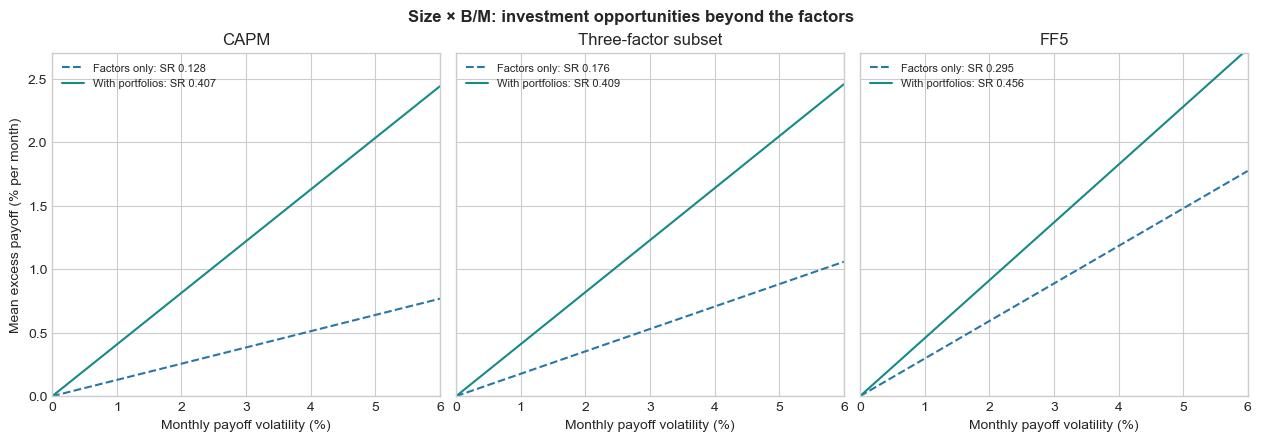

In [14]:
NAVY,BLUE,TEAL="#17324D","#2878A5","#168A86"
fig,axes=plt.subplots(1,3,figsize=(12.5,4.3),constrained_layout=True,sharex=True,sharey=True)
volatility=np.linspace(0,.06,150)
for ax,model in zip(axes,models):
    result=efficiency["size_bm",model]
    base=result["factor_sharpe"]
    augmented=result["augmented_sharpe"]
    ax.plot(volatility*100,volatility*base*100,color=BLUE,ls="--",label=f"Factors only: SR {base:.3f}")
    ax.plot(volatility*100,volatility*augmented*100,color=TEAL,label=f"With portfolios: SR {augmented:.3f}")
    ax.set(title="Three-factor subset" if model=="FF3" else model,
           xlabel="Monthly payoff volatility (%)",xlim=(0,6),ylim=(0,2.7))
    ax.legend(fontsize=8,loc="upper left",frameon=False)
axes[0].set_ylabel("Mean excess payoff (% per month)")
fig.suptitle("Size × B/M: investment opportunities beyond the factors",weight="bold")
plt.show()

For Size × B/M, the factor-only monthly Sharpe rises from approximately 0.128 under CAPM to 0.176 for the three-factor subset and 0.295 for FF5. Allowing the test portfolios raises these values to approximately 0.407, 0.409, and 0.456, respectively. The increase in squared Sharpe is approximately 0.149, 0.136, and 0.120.

The factors become a stronger investment benchmark, but the test portfolios still supply an estimated incremental opportunity beyond FF5. Its GRS statistic is approximately 3.08, with a p-value of $8.7\times10^{-7}$, rejecting the conventional efficiency restriction for this family at 5%. This is evidence conditional on iid normal residuals and the other GRS assumptions. The HAC individual-alpha statistics do not remove those limitations.

These lines show scalable payoff combinations estimated using the entire sample. They do not represent compounded wealth paths, net-of-cost strategies, or portfolios that investors could have selected before observing the history. Their zero intercept is zero excess payoff, because RF has already been accounted for.

### 2.4 Where do pricing errors remain?

The 5×5 portfolios provide 25 test assets for each characteristic family. The alpha heatmaps retain the economic layout of the sorts: rows move from small to big firms, and columns move from low to high B/M, OP, or INV. A successful model should flatten systematic color gradients rather than merely reduce one extreme portfolio's alpha.

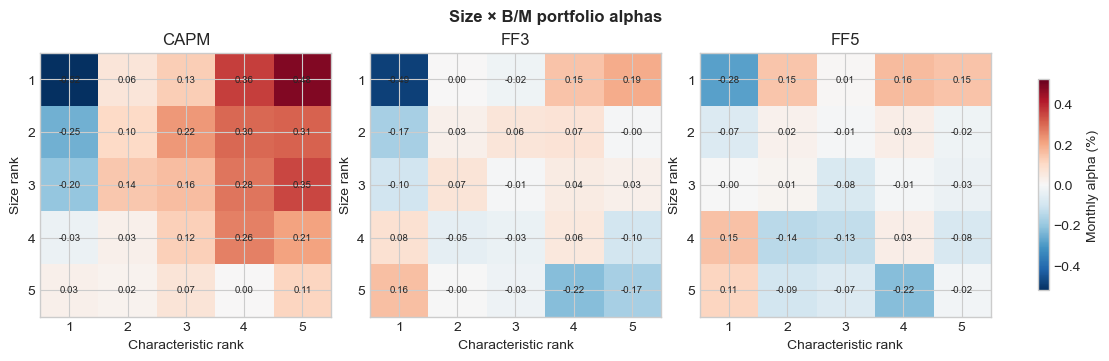

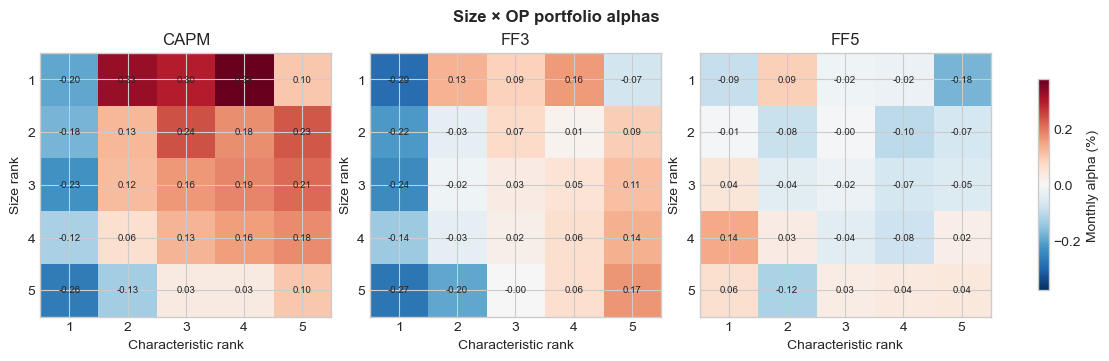

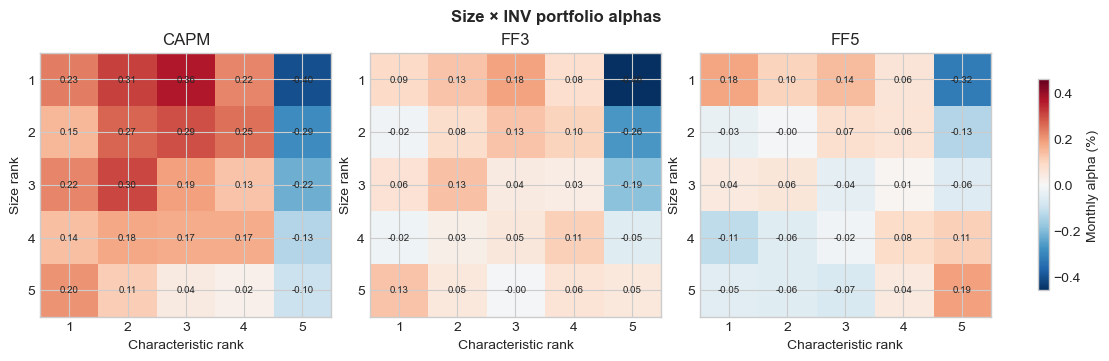

In [15]:
def alpha_grid_5x5(family, model):
    values = regressions[family, model].alpha.rename_axis("asset").reset_index()
    values[["size", "characteristic"]] = values.asset.str.extract(r"S(\d)C(\d)").astype(int)
    return values.pivot(index="size", columns="characteristic", values="alpha") * 100

for family in ["size_bm", "size_op", "size_inv"]:
    grids = {model: alpha_grid_5x5(family, model) for model in models}
    bound = max(abs(grid.to_numpy()).max() for grid in grids.values())
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), constrained_layout=True)
    for ax, (model, grid) in zip(axes, grids.items()):
        image = ax.imshow(grid, cmap="RdBu_r", vmin=-bound, vmax=bound, aspect="auto")
        for (r, c), value in np.ndenumerate(grid.to_numpy()): ax.text(c, r, f"{value:.2f}", ha="center", va="center", fontsize=7)
        ax.set(title=model, xlabel="Characteristic rank", ylabel="Size rank", xticks=range(5), xticklabels=range(1,6), yticks=range(5), yticklabels=range(1,6))
    fig.colorbar(image, ax=axes, shrink=.8, label="Monthly alpha (%)")
    fig.suptitle(f"{labels[family]} portfolio alphas", weight="bold")
    plt.show()


For Size × B/M, FF3 removes much of the CAPM pattern and FF5 produces only a modest further reduction in average absolute alpha. The profitability and investment families make the incremental role of FF5 clearer: RMW and CMA reduce the corresponding alpha gradients, lower average pricing errors, and raise adjusted $R^2$. Size × OP is the strongest result—FF5 leaves three individually significant alphas at 5%, and GRS rejects jointly ($p=0.0089$). Size × B/M and Size × INV still reject, so the additional factors improve these cross-sections without fully pricing them.

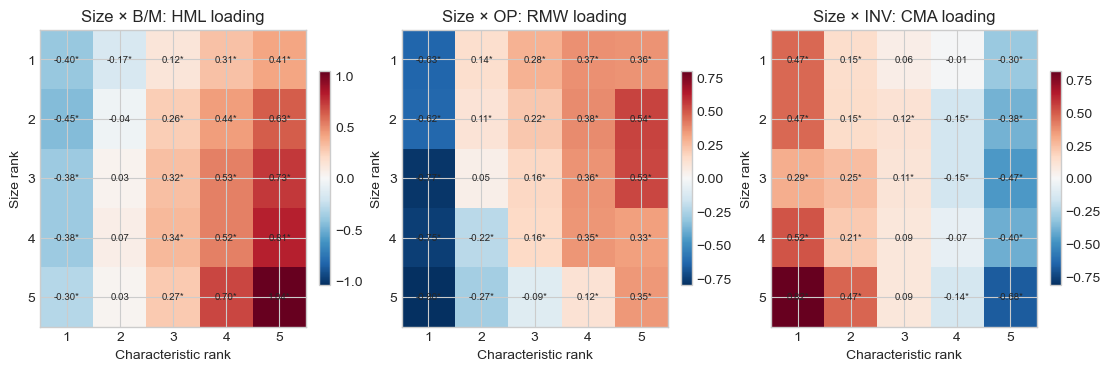

In [16]:
loading_specs = {"size_bm": "HML", "size_op": "RMW", "size_inv": "CMA"}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), constrained_layout=True)
for ax, (family, factor) in zip(axes, loading_specs.items()):
    result = regressions[family, "FF5"]
    values = result[[f"beta_{factor}", f"beta_{factor}_t"]].rename_axis("asset").reset_index()
    values[["size", "characteristic"]] = values.asset.str.extract(r"S(\d)C(\d)").astype(int)
    grid = values.pivot(index="size", columns="characteristic", values=f"beta_{factor}")
    t_grid = values.pivot(index="size", columns="characteristic", values=f"beta_{factor}_t")
    bound = abs(grid.to_numpy()).max()
    image = ax.imshow(grid, cmap="RdBu_r", vmin=-bound, vmax=bound, aspect="auto")
    for (r, c), value in np.ndenumerate(grid.to_numpy()): ax.text(c, r, f"{value:.2f}{'*' if abs(t_grid.to_numpy()[r,c]) >= 1.96 else ''}", ha="center", va="center", fontsize=7)
    ax.set(title=f"{labels[family]}: {factor} loading", xlabel="Characteristic rank", ylabel="Size rank", xticks=range(5), xticklabels=range(1,6), yticks=range(5), yticklabels=range(1,6))
    fig.colorbar(image, ax=ax, shrink=.72)
plt.show()

The loading gradients make the mechanism behind the improved fit visible. HML exposure rises across B/M portfolios, RMW exposure rises across profitability portfolios, and CMA exposure rises toward conservative-investment portfolios. An asterisk marks a loading with an absolute Newey–West $t$-statistic of at least 1.96. Their alignment with the sorting characteristic shows that the factors capture variation associated with the intended characteristics. It does not by itself establish why those dimensions command risk premia.

### 2.5 A harder test: the 2×4×4 portfolios

The 32-portfolio families provide a more conditional challenge. Within small and big firms, they preserve joint variation in two characteristics. Each figure displays small and big firms in separate rows and compares CAPM, FF3, and FF5 in columns.

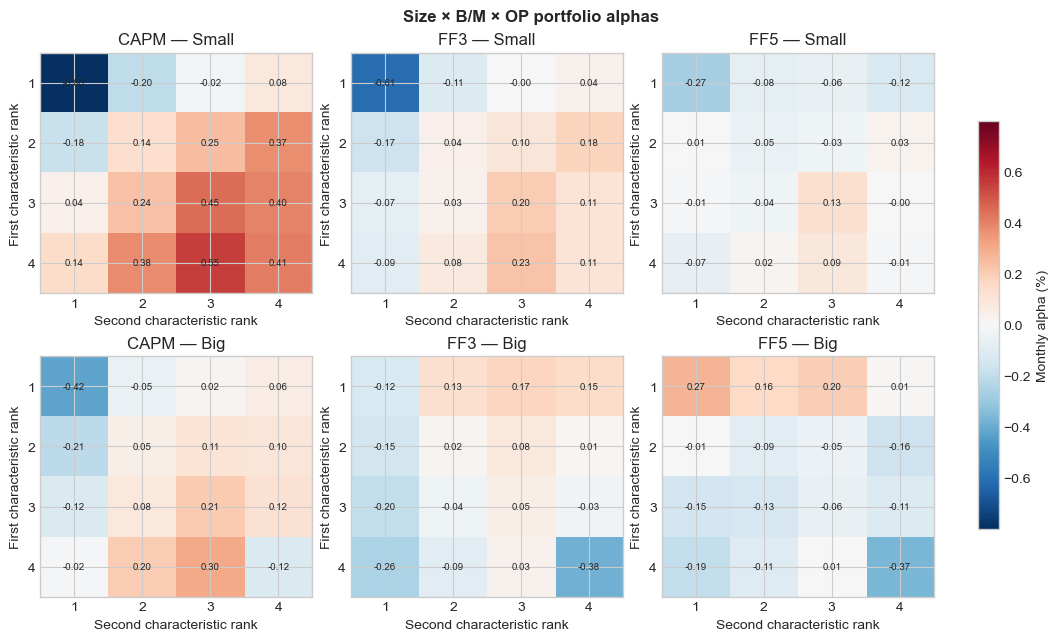

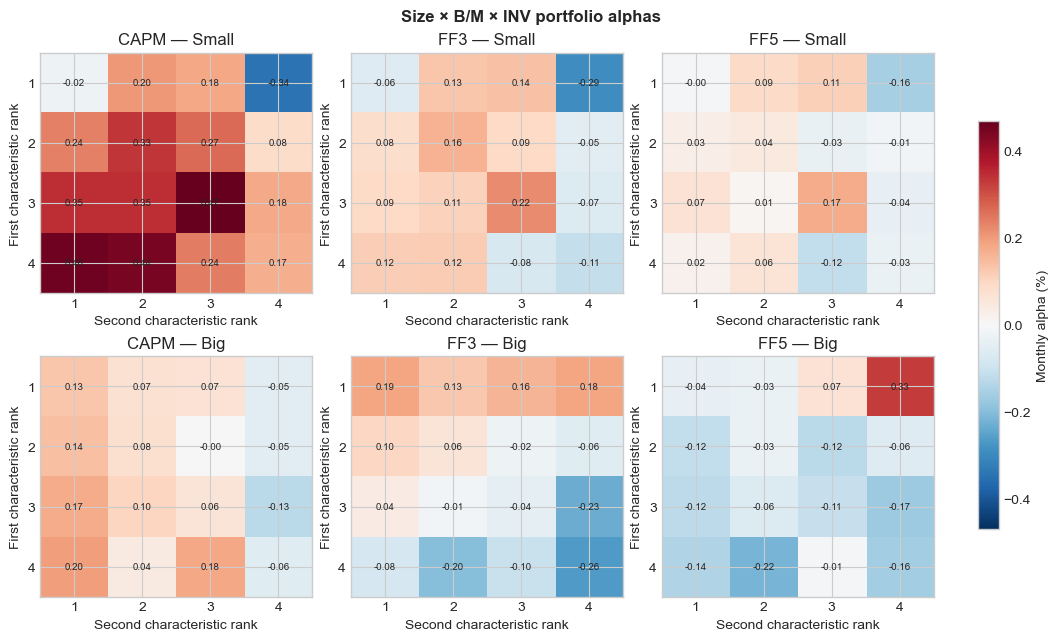

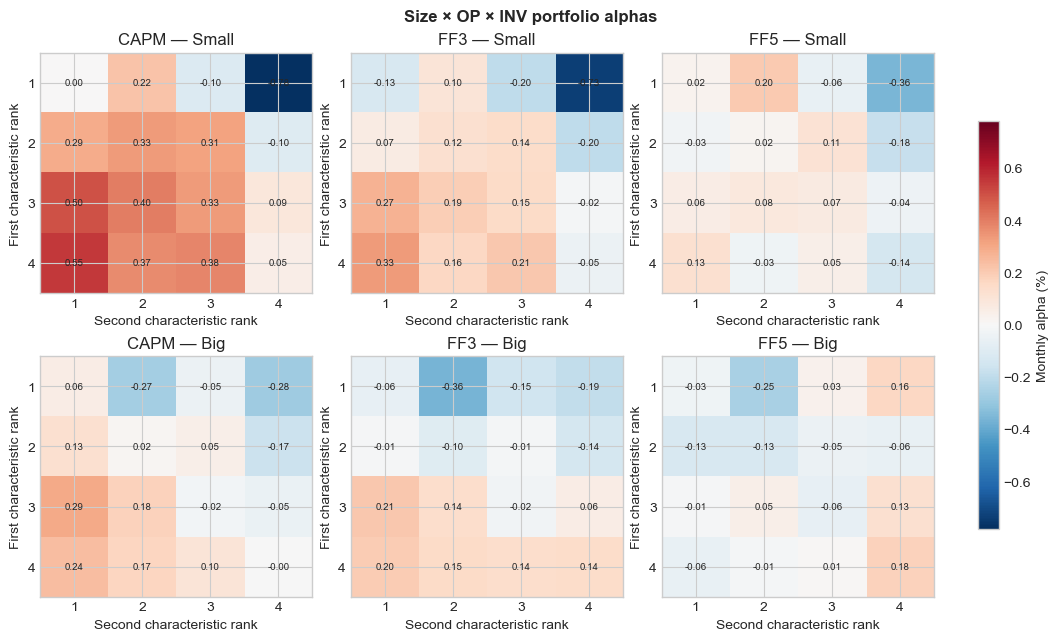

In [17]:
def alpha_grid_2x4x4(family, model, size):
    values = regressions[family, model].alpha.rename_axis("asset").reset_index()
    parsed = values.asset.str.extract(r"([SB])-(\d)-(\d)")
    values[["size", "first", "second"]] = parsed
    values[["first", "second"]] = values[["first", "second"]].astype(int)
    return values.loc[values["size"].eq(size)].pivot(index="first", columns="second", values="alpha") * 100

for family in ["size_bm_op", "size_bm_inv", "size_op_inv"]:
    grids = {(size, model): alpha_grid_2x4x4(family, model, size) for size in ["S", "B"] for model in models}
    bound = max(abs(grid.to_numpy()).max() for grid in grids.values())
    fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.3), constrained_layout=True)
    for row, size in enumerate(["S", "B"]):
        for col, model in enumerate(models):
            ax = axes[row, col]
            grid = grids[size, model]
            image = ax.imshow(grid, cmap="RdBu_r", vmin=-bound, vmax=bound, aspect="auto")
            for (r, c), value in np.ndenumerate(grid.to_numpy()): ax.text(c, r, f"{value:.2f}", ha="center", va="center", fontsize=7)
            ax.set(title=f"{model} — {'Small' if size == 'S' else 'Big'}", xlabel="Second characteristic rank", ylabel="First characteristic rank", xticks=range(4), xticklabels=range(1,5), yticks=range(4), yticklabels=range(1,5))
    fig.colorbar(image, ax=axes, shrink=.75, label="Monthly alpha (%)")
    fig.suptitle(f"{labels[family]} portfolio alphas", weight="bold")
    plt.show()


The conditional portfolios tell the same broad story but impose a harder test. FF5 materially reduces CAPM pricing errors in every family, especially Size × OP × INV, yet the remaining alphas are not uniformly zero. GRS rejects all three FF5 specifications at 5%, although Size × B/M × OP has the largest p-value ($p=0.0207$). Conditioning reveals residual pockets of model failure that can be hidden by averages, particularly where characteristic combinations produce more extreme exposures.

In [18]:
factor_pairs = {"size_bm_op": [("first", "HML"), ("second", "RMW")], "size_bm_inv": [("first", "HML"), ("second", "CMA")], "size_op_inv": [("first", "RMW"), ("second", "CMA")]}
loading_rows = []
for family, pairs in factor_pairs.items():
    result = regressions[family, "FF5"].reset_index()
    parsed = result.asset.str.extract(r"([SB])-(\d)-(\d)")
    result[["size", "first", "second"]] = parsed
    result[["first", "second"]] = result[["first", "second"]].astype(int)
    for dimension, factor in pairs:
        averages = result.groupby(dimension)[f"beta_{factor}"].mean()
        loading_rows.append({"Portfolio set": labels[family], "Sorting dimension": dimension.title(), "Matching factor": factor, "Low-rank beta": averages.loc[1], "High-rank beta": averages.loc[4], "High − low beta": averages.loc[4] - averages.loc[1]})
display(pd.DataFrame(loading_rows).set_index(["Portfolio set", "Matching factor"]))

Sorting dimension  Low-rank beta  \
Portfolio set    Matching factor                                    
Size × B/M × OP  HML                         First        -0.3178   
                 RMW                        Second        -0.4633   
Size × B/M × INV HML                         First        -0.2750   
                 CMA                        Second         0.5314   
Size × OP × INV  RMW                         First        -0.5294   
                 CMA                        Second         0.5084   

                                  High-rank beta  High − low beta  
Portfolio set    Matching factor                                   
Size × B/M × OP  HML                      0.7098           1.0276  
                 RMW                      0.3841           0.8474  
Size × B/M × INV HML                      0.6826           0.9576  
                 CMA                     -0.3750          -0.9064  
Size × OP × INV  RMW                      0.3955           0.9248  
                 CMA                     -0.4214          -0.9297

The loading spreads confirm that the conditional sorts generate the intended risk-exposure variation. Moving from low to high B/M or OP increases exposure to HML or RMW. Investment is ordered from low investment (conservative) to high investment (aggressive), so CMA exposure moves in the opposite direction and becomes more negative as the investment rank rises. This is precisely why the portfolios are informative test assets: they create a broad range of model-implied exposures while remaining diversified portfolios rather than individual stocks.

### 2.6 What the evidence establishes

The FF5 model improves materially on CAPM and generally on FF3 for these characteristic-sorted portfolios: average absolute alphas fall, adjusted $R^2$ rises, and characteristic-factor loadings align with the portfolios' sorting dimensions. The improvement is strongest when profitability and investment are present.

The conclusion remains deliberately limited. All six FF5 GRS tests reject joint zero alpha, so FF5 is not a complete description of every tested cross-section. Conversely, rejection does not identify whether the failure reflects omitted risk, mispricing, measurement error, or the particular sample and test assets. These tests rank empirical models by how well they organize returns. They do not settle the economic origin of the factors.

The Sharpe comparisons give these pricing results their portfolio meaning: the supplied factors organize a larger share of the estimated investment opportunity, while added test portfolios still improve the in-sample optimum. GRS asks whether the improvement is statistically consistent with zero population alpha under its maintained assumptions. The estimated gains do not establish future performance, economic identification, or feasibility after financing, costs, and position constraints.

## Covariance conventions

The displayed GRS formula uses residual and factor covariance matrices divided by $T$. Internally, the package estimates residual covariance using divisor $T-K-1$ and factor covariance using divisor $T-1$, then applies the corresponding finite-sample adjustments. This gives exactly the displayed statistic. The empirical Sharpe-ratio tables retain divisor-$T-1$ covariance, consistent with notebook 06.


## References

- Gibbons, M. R., Ross, S. A., and Shanken, J. (1989). A test of the efficiency of a given portfolio. *Econometrica*, 57(5), 1121–1152. [DOI](https://doi.org/10.2307/1913625).
- Kenneth R. French Data Library. [Factor and portfolio data](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html).
